# EEE3032 – Stage 6: Evaluate the BoVW Experiments

This notebook compares the supplied global RGB histogram baseline with the eight SIFT-based Bag-of-Visual-Words (BoVW) configurations prepared in Stages 3–5.

## What this stage does

1. Load the official gallery and development split.
2. Calculate the supplied global RGB histogram baseline.
3. Load the eight BoVW feature matrices saved in Stage 5.
4. Evaluate all methods on the same 100 development queries.
5. Compare mAP, mean P@10 and per-group performance.
6. Calculate paired bootstrap intervals for the difference in per-query AP.
7. Save representative baseline-versus-BoVW retrieval examples.



## 1. Connect to the project and set paths

Place this notebook in the project's `notebooks/` folder. Set `PROJECT_ROOT` to the folder containing `cvpr/`, `visual_search/` and `split_manifest.csv`.

In [4]:
from pathlib import Path
import sys
import csv
import re

import numpy as np
import matplotlib.pyplot as plt

# Mount Google Drive when this notebook is running in Colab.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3"
)
DATASET_SOURCE = Path(
    "/content/drive/MyDrive/cvpr_coursework/MSRC_ObjCategImageDatabase_v2"
)

if not (PROJECT_ROOT / "cvpr").is_dir():
    raise FileNotFoundError("Set PROJECT_ROOT to the folder containing cvpr/.")
if not (PROJECT_ROOT / "visual_search").is_dir():
    raise FileNotFoundError("The visual_search package is missing.")

# Make the project modules available to this notebook.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project folder:", PROJECT_ROOT)
print("Dataset source:", DATASET_SOURCE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3
Dataset source: /content/drive/MyDrive/cvpr_coursework/MSRC_ObjCategImageDatabase_v2


## 2. Import the dataset, retrieval and evaluation functions

The evaluation functions are supplied in the coursework's `cvpr` package. We use the same evaluation implementation for the baseline and every BoVW configuration.

In [5]:
from cvpr.dataset import load_split_records, read_rgb
from cvpr.baseline import global_rgb_histogram
from cvpr.retrieval import compute_descriptors, euclidean_distances
from cvpr.evaluation import evaluate_retrieval, per_category_summary

from visual_search.vocabulary import VOCABULARY_CONFIGS

## 3. Load the official split

We evaluate on the 391 gallery images and 100 development queries. The test records are loaded only to verify the official split size; they are not used in any calculation below.

In [6]:
MANIFEST = PROJECT_ROOT / "split_manifest.csv"

gallery, dev, test_records = load_split_records(
    DATASET_SOURCE,
    manifest_path=MANIFEST,
    extract_dir=PROJECT_ROOT / "data",
)

assert len(gallery) == 391
assert len(dev) == 100
assert len(test_records) == 100

print(f"Gallery images: {len(gallery)}")
print(f"Development queries: {len(dev)}")
print(f"Final test records: {len(test_records)} (not evaluated in Stage 6)")

Gallery images: 391
Development queries: 100
Final test records: 100 (not evaluated in Stage 6)


## 4. Set evaluation paths and experiment settings

The eight Stage 5 files should be in `bovw_features/stage5_dev/`. Every BoVW representation has 100 visual words, so each image is represented by 100 values.

In [7]:
K = 100
P_AT_K = 10

FEATURES_DIR = PROJECT_ROOT / "bovw_features" / "stage5_dev"
RESULTS_DIR = PROJECT_ROOT / "results"
VISUAL_DIR = RESULTS_DIR / "stage6_visual_examples"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
VISUAL_DIR.mkdir(parents=True, exist_ok=True)

if not FEATURES_DIR.is_dir():
    raise FileNotFoundError(f"Stage 5 feature folder not found: {FEATURES_DIR}")

print("BoVW configurations:", len(VOCABULARY_CONFIGS))
print("Vocabulary size:", K)
print("Evaluation metric: mAP and mean P@10")
print("Distance: Euclidean")

BoVW configurations: 8
Vocabulary size: 100
Evaluation metric: mAP and mean P@10
Distance: Euclidean


## 5. Calculate the global RGB histogram baseline

The baseline uses the supplied 4-bin-per-channel RGB histogram (64 values per image). We calculate the gallery and development descriptors using the same image records used by the BoVW systems.

If the baseline feature file already exists and its filename order matches the manifest, it is reused. Otherwise, the descriptors are calculated and saved.

In [8]:
BASELINE_FEATURE_FILE = (
    PROJECT_ROOT / "bovw_features" / "stage6_eval" / "global_rgb_baseline.npz"
)
BASELINE_FEATURE_FILE.parent.mkdir(parents=True, exist_ok=True)

gallery_names = np.asarray([record.filename for record in gallery])
dev_names = np.asarray([record.filename for record in dev])

reuse_baseline = False

if BASELINE_FEATURE_FILE.exists():
    with np.load(BASELINE_FEATURE_FILE, allow_pickle=False) as saved:
        saved_gallery_names = saved["gallery_filenames"].astype(str)
        saved_dev_names = saved["query_filenames"].astype(str)

        if (
            np.array_equal(saved_gallery_names, gallery_names)
            and np.array_equal(saved_dev_names, dev_names)
            and int(saved["bins_per_channel"]) == 4
        ):
            baseline_gallery_features = np.asarray(
                saved["gallery_features"], dtype=np.float32
            )
            baseline_dev_features = np.asarray(
                saved["query_features"], dtype=np.float32
            )
            reuse_baseline = True

if not reuse_baseline:
    baseline_gallery_features = compute_descriptors(
        gallery, global_rgb_histogram
    )
    baseline_dev_features = compute_descriptors(
        dev, global_rgb_histogram
    )

    np.savez_compressed(
        BASELINE_FEATURE_FILE,
        gallery_features=baseline_gallery_features,
        query_features=baseline_dev_features,
        gallery_filenames=gallery_names,
        query_filenames=dev_names,
        bins_per_channel=np.asarray(4),
    )

assert baseline_gallery_features.shape == (391, 64)
assert baseline_dev_features.shape == (100, 64)
assert np.isfinite(baseline_gallery_features).all()
assert np.isfinite(baseline_dev_features).all()

print("Reused saved baseline features:", reuse_baseline)
print("Baseline gallery matrix:", baseline_gallery_features.shape)
print("Baseline development matrix:", baseline_dev_features.shape)

Reused saved baseline features: True
Baseline gallery matrix: (391, 64)
Baseline development matrix: (100, 64)


## 6. Evaluate the baseline

The supplied baseline uses Euclidean distance between its L1-normalised colour histograms. We record the mean Average Precision (mAP), mean Precision@10 and the AP/P@10 for every individual development query.

In [9]:
baseline_summary, baseline_query_rows = evaluate_retrieval(
    query_records=dev,
    query_features=baseline_dev_features,
    gallery_records=gallery,
    gallery_features=baseline_gallery_features,
    distance_fn=euclidean_distances,
    k=P_AT_K,
)

overall_rows = [{
    "method": "Global RGB histogram",
    "configuration": "baseline_rgb",
    "method_type": "Baseline",
    "mAP": baseline_summary["mAP"],
    "mean_P@10": baseline_summary["mean_P@10"],
    "n_queries": baseline_summary["n_queries"],
}]

per_query_rows = []
for row in baseline_query_rows:
    per_query_rows.append({
        "method": "Global RGB histogram",
        "configuration": "baseline_rgb",
        **row,
    })

baseline_group_rows = per_category_summary(
    baseline_query_rows, k=P_AT_K
)
per_group_rows = [
    {
        "method": "Global RGB histogram",
        "configuration": "baseline_rgb",
        **row,
    }
    for row in baseline_group_rows
]

print(f"Baseline development mAP: {baseline_summary['mAP']:.4f}")
print(f"Baseline mean P@10:      {baseline_summary['mean_P@10']:.4f}")

Baseline development mAP: 0.1592
Baseline mean P@10:      0.1830


## 7. Load and validate the eight Stage 5 feature files

Each saved file contains the gallery matrix, development-query matrix, gallery-fitted IDF weights and the filenames that define row order.

The checks below are important: a feature matrix is only valid for evaluation if its rows correspond to the same image order as the records.

In [10]:
CONFIG_DISPLAY_NAMES = {
    "detected_sift": "Detected SIFT",
    "detected_rootsift": "Detected RootSIFT",
    "detected_opponentsift": "Detected OpponentSIFT",
    "detected_root_opponentsift": "Detected RootOpponentSIFT",
    "dense_sift": "Dense SIFT",
    "dense_rootsift": "Dense RootSIFT",
    "dense_opponentsift": "Dense OpponentSIFT",
    "dense_root_opponentsift": "Dense RootOpponentSIFT",
}


def load_stage5_feature_file(config):
    """Load one Stage 5 feature file and check its metadata and row order."""
    feature_file = FEATURES_DIR / f"{config.name}_K{K}.npz"

    if not feature_file.exists():
        raise FileNotFoundError(f"Missing Stage 5 feature file: {feature_file}")

    with np.load(feature_file, allow_pickle=False) as saved:
        saved_config = str(saved["configuration"].item())
        saved_k = int(saved["K"])

        gallery_features = np.asarray(
            saved["gallery_features"], dtype=np.float32
        )
        query_features = np.asarray(
            saved["query_features"], dtype=np.float32
        )
        idf = np.asarray(saved["idf"], dtype=np.float32).ravel()

        saved_gallery_names = saved["gallery_filenames"].astype(str)
        saved_query_names = saved["query_filenames"].astype(str)

    # Check that this is the correct configuration and vocabulary size.
    if saved_config != config.name:
        raise ValueError(
            f"Expected {config.name}, but the file contains {saved_config}."
        )
    if saved_k != K:
        raise ValueError(f"Expected K={K}, but the file contains K={saved_k}.")

    # Confirm that each row still refers to the correct image.
    if not np.array_equal(saved_gallery_names, gallery_names):
        raise ValueError(f"Gallery filename order mismatch in {feature_file.name}.")
    if not np.array_equal(saved_query_names, dev_names):
        raise ValueError(f"Development filename order mismatch in {feature_file.name}.")

    # Check dimensions and numerical validity.
    if gallery_features.shape != (391, K):
        raise ValueError(
            f"Unexpected gallery matrix shape for {config.name}: "
            f"{gallery_features.shape}"
        )
    if query_features.shape != (100, K):
        raise ValueError(
            f"Unexpected development matrix shape for {config.name}: "
            f"{query_features.shape}"
        )
    if idf.shape != (K,):
        raise ValueError(f"Unexpected IDF shape for {config.name}: {idf.shape}")

    for array_name, values in [
        ("gallery features", gallery_features),
        ("development features", query_features),
        ("IDF", idf),
    ]:
        if not np.isfinite(values).all():
            raise ValueError(f"{config.name} contains invalid {array_name} values.")

    # Non-zero TF-IDF vectors should have unit L2 norm.
    gallery_norms = np.linalg.norm(gallery_features, axis=1)
    query_norms = np.linalg.norm(query_features, axis=1)

    if not np.allclose(gallery_norms[gallery_norms > 0], 1.0, atol=1e-5):
        raise ValueError(f"Gallery vectors are not L2-normalised for {config.name}.")
    if not np.allclose(query_norms[query_norms > 0], 1.0, atol=1e-5):
        raise ValueError(f"Development vectors are not L2-normalised for {config.name}.")

    return gallery_features, query_features, idf, feature_file


print("Checking Stage 5 feature files...")
for config in VOCABULARY_CONFIGS:
    g_features, q_features, idf, feature_file = load_stage5_feature_file(config)
    print(
        f"{config.name:32s} "
        f"gallery={g_features.shape}, dev={q_features.shape}, "
        f"zero gallery={np.sum(np.linalg.norm(g_features, axis=1) == 0)}, "
        f"zero dev={np.sum(np.linalg.norm(q_features, axis=1) == 0)}"
    )

Checking Stage 5 feature files...
detected_sift                    gallery=(391, 100), dev=(100, 100), zero gallery=0, zero dev=0
detected_rootsift                gallery=(391, 100), dev=(100, 100), zero gallery=0, zero dev=0
detected_opponentsift            gallery=(391, 100), dev=(100, 100), zero gallery=0, zero dev=0
detected_root_opponentsift       gallery=(391, 100), dev=(100, 100), zero gallery=0, zero dev=0
dense_sift                       gallery=(391, 100), dev=(100, 100), zero gallery=0, zero dev=0
dense_rootsift                   gallery=(391, 100), dev=(100, 100), zero gallery=0, zero dev=0
dense_opponentsift               gallery=(391, 100), dev=(100, 100), zero gallery=0, zero dev=0
dense_root_opponentsift          gallery=(391, 100), dev=(100, 100), zero gallery=0, zero dev=0


## 8. Evaluate all eight BoVW configurations

We now evaluate each BoVW feature matrix against the same 391 gallery images and the same 100 development queries.

The distance function and relevance definition are identical to the baseline evaluation. The only difference is the image representation.

In [11]:
bovw_features_by_method = {}

for number, config in enumerate(VOCABULARY_CONFIGS, start=1):
    method_name = CONFIG_DISPLAY_NAMES[config.name]
    print(f"[{number}/{len(VOCABULARY_CONFIGS)}] Evaluating {method_name}...")

    gallery_features, query_features, idf, feature_file = (
        load_stage5_feature_file(config)
    )

    summary, query_rows = evaluate_retrieval(
        query_records=dev,
        query_features=query_features,
        gallery_records=gallery,
        gallery_features=gallery_features,
        distance_fn=euclidean_distances,
        k=P_AT_K,
    )

    group_rows = per_category_summary(query_rows, k=P_AT_K)

    overall_rows.append({
        "method": method_name,
        "configuration": config.name,
        "method_type": "BoVW",
        "mAP": summary["mAP"],
        "mean_P@10": summary["mean_P@10"],
        "n_queries": summary["n_queries"],
    })

    for row in query_rows:
        per_query_rows.append({
            "method": method_name,
            "configuration": config.name,
            **row,
        })

    for row in group_rows:
        per_group_rows.append({
            "method": method_name,
            "configuration": config.name,
            **row,
        })

    # Keep feature arrays in memory for the comparison plots later.
    bovw_features_by_method[config.name] = (
        gallery_features, query_features
    )

    print(
        f"    mAP={summary['mAP']:.4f}, "
        f"mean P@10={summary['mean_P@10']:.4f}"
    )

print("\nAll eight BoVW configurations have been evaluated.")

[1/8] Evaluating Detected SIFT...
    mAP=0.1646, mean P@10=0.2100
[2/8] Evaluating Detected RootSIFT...
    mAP=0.1732, mean P@10=0.2170
[3/8] Evaluating Detected OpponentSIFT...
    mAP=0.1989, mean P@10=0.2710
[4/8] Evaluating Detected RootOpponentSIFT...
    mAP=0.2117, mean P@10=0.2800
[5/8] Evaluating Dense SIFT...
    mAP=0.2436, mean P@10=0.2950
[6/8] Evaluating Dense RootSIFT...
    mAP=0.2368, mean P@10=0.2880
[7/8] Evaluating Dense OpponentSIFT...
    mAP=0.2511, mean P@10=0.2940
[8/8] Evaluating Dense RootOpponentSIFT...
    mAP=0.2511, mean P@10=0.2910

All eight BoVW configurations have been evaluated.


## 9. Rank the methods and save the development results

The highest development mAP is the leading candidate for the final evaluation. It is not yet a final test result.

We also save per-query AP and P@10 and per-group summaries so that the report can explain where each method succeeds and fails.

In [12]:
# Put the baseline and all BoVW methods in descending mAP order.
overall_rows_sorted = sorted(
    overall_rows,
    key=lambda row: row["mAP"],
    reverse=True,
)

print(f"{'Method':34s} {'mAP':>10s} {'Mean P@10':>12s}")
print("-" * 60)
for row in overall_rows_sorted:
    print(
        f"{row['method']:34s} "
        f"{row['mAP']:10.4f} "
        f"{row['mean_P@10']:12.4f}"
    )

best_bovw_row = max(
    [row for row in overall_rows if row["method_type"] == "BoVW"],
    key=lambda row: row["mAP"],
)

print("\nLeading BoVW development candidate:", best_bovw_row["method"])
print(f"Development mAP: {best_bovw_row['mAP']:.4f}")
print("Do not evaluate the test queries yet.")

Method                                    mAP    Mean P@10
------------------------------------------------------------
Dense RootOpponentSIFT                 0.2511       0.2910
Dense OpponentSIFT                     0.2511       0.2940
Dense SIFT                             0.2436       0.2950
Dense RootSIFT                         0.2368       0.2880
Detected RootOpponentSIFT              0.2117       0.2800
Detected OpponentSIFT                  0.1989       0.2710
Detected RootSIFT                      0.1732       0.2170
Detected SIFT                          0.1646       0.2100
Global RGB histogram                   0.1592       0.1830

Leading BoVW development candidate: Dense RootOpponentSIFT
Development mAP: 0.2511
Do not evaluate the test queries yet.


In [13]:
def save_rows_to_csv(rows, output_file):
    """Write a list of dictionaries to a CSV file."""
    if not rows:
        raise ValueError(f"No rows to save to {output_file}.")

    output_file.parent.mkdir(parents=True, exist_ok=True)
    with output_file.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)


overall_file = RESULTS_DIR / "stage6_dev_overall.csv"
per_group_file = RESULTS_DIR / "stage6_dev_by_group.csv"
per_query_file = RESULTS_DIR / "stage6_dev_per_query.csv"

save_rows_to_csv(overall_rows_sorted, overall_file)
save_rows_to_csv(per_group_rows, per_group_file)
save_rows_to_csv(per_query_rows, per_query_file)

print("Saved:", overall_file)
print("Saved:", per_group_file)
print("Saved:", per_query_file)

Saved: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage6_dev_overall.csv
Saved: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage6_dev_by_group.csv
Saved: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage6_dev_per_query.csv


## 10. Plot overall mAP and mean P@10

These charts show whether the BoVW methods improve over the global colour baseline. Interpret small differences cautiously; development results are used to select a candidate and can be optimistic after comparing several configurations.

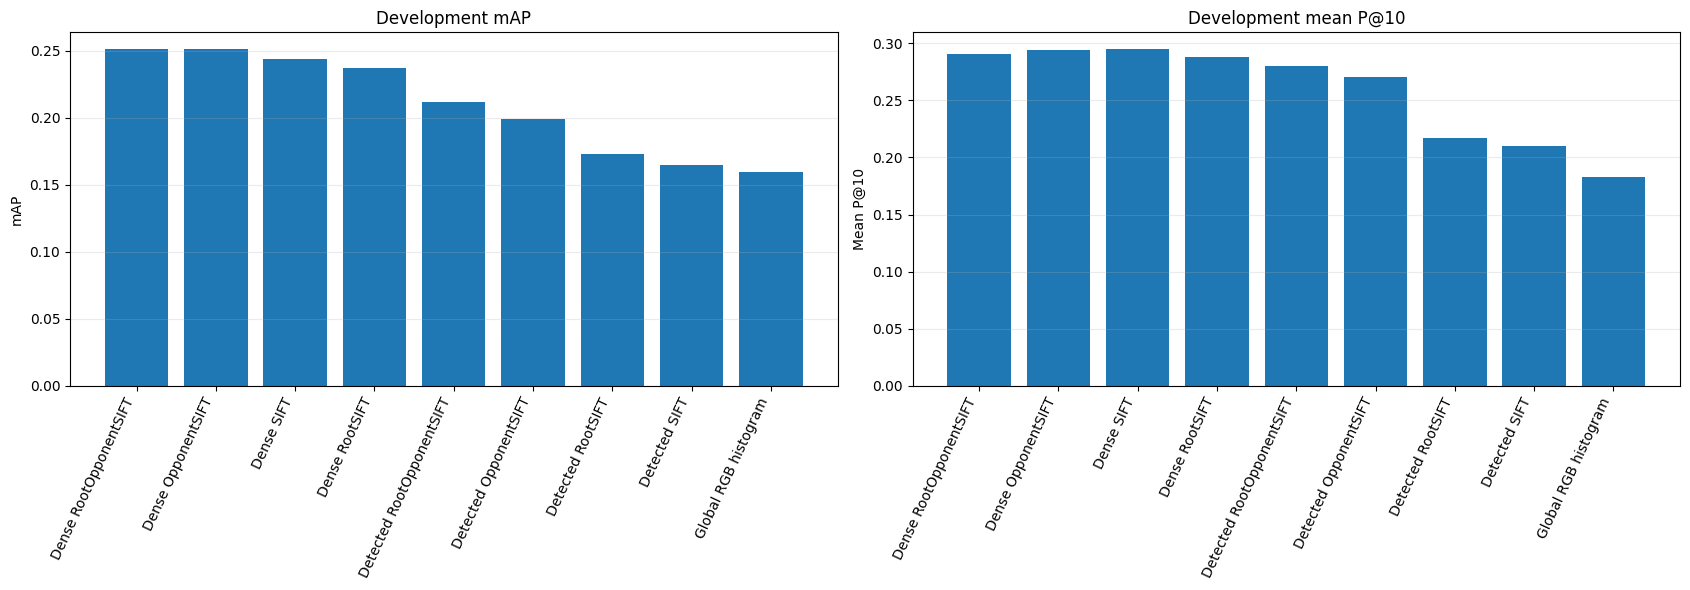

Saved: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage6_dev_overall_comparison.png


In [14]:
plot_labels = [row["method"] for row in overall_rows_sorted]
map_values = [row["mAP"] for row in overall_rows_sorted]
p10_values = [row["mean_P@10"] for row in overall_rows_sorted]

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

axes[0].bar(range(len(plot_labels)), map_values)
axes[0].set_title("Development mAP")
axes[0].set_ylabel("mAP")
axes[0].set_xticks(range(len(plot_labels)))
axes[0].set_xticklabels(plot_labels, rotation=65, ha="right")
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(range(len(plot_labels)), p10_values)
axes[1].set_title("Development mean P@10")
axes[1].set_ylabel("Mean P@10")
axes[1].set_xticks(range(len(plot_labels)))
axes[1].set_xticklabels(plot_labels, rotation=65, ha="right")
axes[1].grid(axis="y", alpha=0.25)

fig.tight_layout()
overall_plot_file = RESULTS_DIR / "stage6_dev_overall_comparison.png"
fig.savefig(overall_plot_file, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", overall_plot_file)

## 11. Compare per-group mAP

The overall mAP can hide large differences between the 20 retrieval groups. This heatmap shows development mAP for every method and group.

There are five development queries per group, so group-level values are useful diagnostics but should be interpreted cautiously.

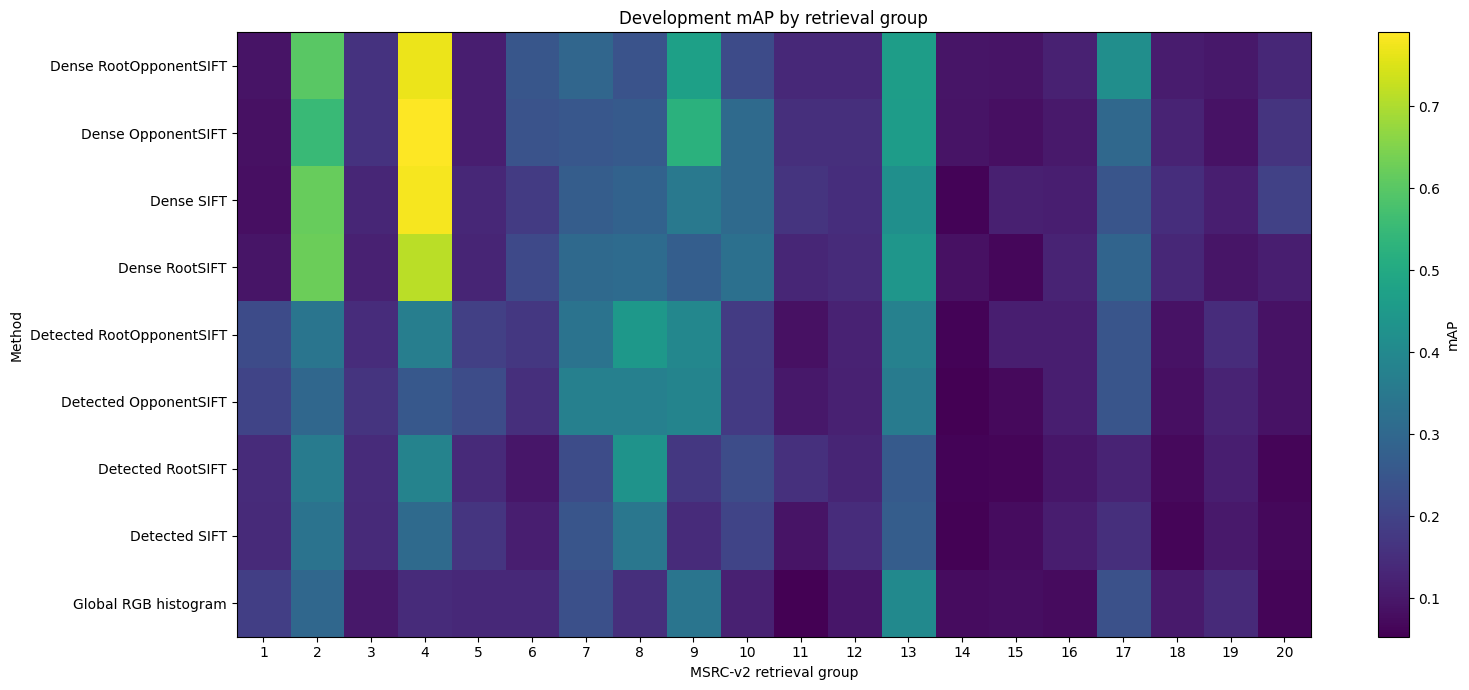

Saved: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage6_dev_per_group_heatmap.png


In [15]:
methods_in_plot = [row["method"] for row in overall_rows_sorted]
categories = sorted({int(record.category) for record in dev})

group_lookup = {
    (row["method"], int(row["category"])): float(row["mAP"])
    for row in per_group_rows
}

group_map_matrix = np.array([
    [group_lookup.get((method, category), np.nan) for category in categories]
    for method in methods_in_plot
], dtype=float)

fig, ax = plt.subplots(figsize=(16, 7))
image = ax.imshow(group_map_matrix, aspect="auto", interpolation="nearest")
ax.set_title("Development mAP by retrieval group")
ax.set_xlabel("MSRC-v2 retrieval group")
ax.set_ylabel("Method")
ax.set_xticks(range(len(categories)))
ax.set_xticklabels(categories)
ax.set_yticks(range(len(methods_in_plot)))
ax.set_yticklabels(methods_in_plot)

colourbar = fig.colorbar(image, ax=ax)
colourbar.set_label("mAP")
fig.tight_layout()

group_plot_file = RESULTS_DIR / "stage6_dev_per_group_heatmap.png"
fig.savefig(group_plot_file, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", group_plot_file)

## 12. Paired bootstrap: compare per-query AP against the baseline

Each method is evaluated on exactly the same development queries. A paired bootstrap resamples queries within each retrieval group and calculates the difference in AP between a BoVW method and the RGB baseline.

The 95% interval describes variation across resampled development queries. This is an exploratory uncertainty estimate, not a formal correction for selecting the best of eight configurations.

In [16]:
# Store AP values in manifest order so the same sampled queries are paired.
baseline_ap = np.array(
    [row["AP"] for row in baseline_query_rows], dtype=float
)

category_array = np.asarray(
    [record.category for record in dev], dtype=int
)
category_indices = {
    category: np.flatnonzero(category_array == category)
    for category in sorted(set(category_array))
}


def paired_stratified_bootstrap(
    method_ap,
    reference_ap,
    category_indices,
    n_bootstrap=3000,
    random_seed=3032,
):
    """Bootstrap the mean paired AP difference, preserving group counts."""
    method_ap = np.asarray(method_ap, dtype=float)
    reference_ap = np.asarray(reference_ap, dtype=float)

    if method_ap.shape != reference_ap.shape:
        raise ValueError("The AP arrays must have the same shape.")

    rng = np.random.default_rng(random_seed)
    differences = np.empty(n_bootstrap, dtype=float)

    for bootstrap_index in range(n_bootstrap):
        # Sample within each category so every group keeps its query count.
        sampled_indices = np.concatenate([
            rng.choice(indices, size=len(indices), replace=True)
            for indices in category_indices.values()
        ])

        paired_difference = method_ap[sampled_indices] - reference_ap[sampled_indices]
        differences[bootstrap_index] = paired_difference.mean()

    return {
        "delta_mAP": float(np.mean(method_ap - reference_ap)),
        "ci_lower_95": float(np.percentile(differences, 2.5)),
        "ci_upper_95": float(np.percentile(differences, 97.5)),
        "bootstrap_fraction_positive": float(np.mean(differences > 0)),
        "n_bootstrap": n_bootstrap,
    }


bootstrap_rows = []

for config in VOCABULARY_CONFIGS:
    method_name = CONFIG_DISPLAY_NAMES[config.name]
    method_rows = [
        row for row in per_query_rows
        if row["configuration"] == config.name
    ]
    method_ap = np.array([row["AP"] for row in method_rows], dtype=float)

    result = paired_stratified_bootstrap(
        method_ap,
        baseline_ap,
        category_indices,
        n_bootstrap=3000,
        random_seed=3032,
    )

    bootstrap_rows.append({
        "method": method_name,
        "configuration": config.name,
        **result,
    })

bootstrap_file = RESULTS_DIR / "stage6_paired_bootstrap_vs_baseline.csv"
save_rows_to_csv(bootstrap_rows, bootstrap_file)

print(
    f"{'Method':34s} {'Delta mAP':>11s} "
    f"{'95% interval':>22s} {'P(delta > 0)':>14s}"
)
print("-" * 86)

for row in bootstrap_rows:
    interval = f"[{row['ci_lower_95']:.4f}, {row['ci_upper_95']:.4f}]"
    print(
        f"{row['method']:34s} "
        f"{row['delta_mAP']:11.4f} "
        f"{interval:>22s} "
        f"{row['bootstrap_fraction_positive']:14.3f}"
    )

print("\nSaved:", bootstrap_file)

Method                               Delta mAP           95% interval   P(delta > 0)
--------------------------------------------------------------------------------------
Detected SIFT                           0.0054      [-0.0126, 0.0235]          0.714
Detected RootSIFT                       0.0140      [-0.0032, 0.0322]          0.946
Detected OpponentSIFT                   0.0397       [0.0194, 0.0604]          1.000
Detected RootOpponentSIFT               0.0525       [0.0312, 0.0743]          1.000
Dense SIFT                              0.0844       [0.0594, 0.1118]          1.000
Dense RootSIFT                          0.0776       [0.0526, 0.1050]          1.000
Dense OpponentSIFT                      0.0919       [0.0665, 0.1185]          1.000
Dense RootOpponentSIFT                  0.0919       [0.0674, 0.1178]          1.000

Saved: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage6_paired_bootstrap_vs_baseline.csv


## 13. Inspect representative retrieval comparisons

The next cell identifies two development queries where the leading BoVW candidate changes AP most favourably relative to the colour baseline, and two where it changes AP least favourably.

For each query, the figure shows the query plus the top five results from the colour baseline and the selected BoVW candidate.

These are diagnostic development examples. They are not final test examples and should not be treated as independent evidence after using them to choose the candidate.

In [17]:

from cvpr.evaluation import average_precision, precision_at_k

# Use the best BoVW configuration selected on development mAP.
best_configuration = best_bovw_row["configuration"]
best_method_name = best_bovw_row["method"]

best_gallery_features, best_dev_features = (
    bovw_features_by_method[best_configuration]
)

# Re-evaluate the selected method on the same development queries.
best_query_summary, best_query_rows = evaluate_retrieval(
    query_records=dev,
    query_features=best_dev_features,
    gallery_records=gallery,
    gallery_features=best_gallery_features,
    distance_fn=euclidean_distances,
    k=P_AT_K,
)

# Check that both evaluations contain the same queries in the same order.
assert len(baseline_query_rows) == len(dev)
assert len(best_query_rows) == len(dev)

for i, record in enumerate(dev):
    for rows, method in [
        (baseline_query_rows, "Baseline"),
        (best_query_rows, "BoVW"),
    ]:
        filename = rows[i].get(
            "filename", rows[i].get("query_filename")
        )
        if filename is not None:
            assert filename == record.filename, (
                f"{method} query order mismatch at index {i}"
            )

baseline_ap_by_query = np.array(
    [row["AP"] for row in baseline_query_rows]
)
best_ap_by_query = np.array(
    [row["AP"] for row in best_query_rows]
)

ap_changes = best_ap_by_query - baseline_ap_by_query

# Select two largest improvements and two largest decreases.
best_relative_indices = np.argsort(ap_changes)[-2:][::-1]
worst_relative_indices = np.argsort(ap_changes)[:2]

example_indices = list(best_relative_indices) + list(worst_relative_indices)

example_labels = (
    ["Largest AP improvement"] * 2
    + ["Largest AP decrease"] * 2
)


def show_baseline_vs_bovw(query_index, top_k=5):

    query_record = dev[query_index]

    methods = [
        (
            "Global RGB baseline",
            baseline_dev_features[query_index],
            baseline_gallery_features,
            baseline_ap_by_query[query_index],
            baseline_query_rows[query_index],
        ),
        (
            best_method_name,
            best_dev_features[query_index],
            best_gallery_features,
            best_ap_by_query[query_index],
            best_query_rows[query_index],
        ),
    ]

    fig, axes = plt.subplots(
        2, top_k + 1,
        figsize=(3.1 * (top_k + 1), 7)
    )

    for row_index, (
        method_label, query_feature, gallery_matrix, reported_ap, query_result
    ) in enumerate(methods):

        distances = euclidean_distances(
            query_feature, gallery_matrix
        )

        ranked_indices = np.argsort(distances)

        # Independently calculate AP from the displayed ranking.
        relevance = np.array([
            gallery[int(i)].category == query_record.category
            for i in ranked_indices
        ])

        total_relevant = sum(
            record.category == query_record.category
            for record in gallery
        )

        displayed_ap = average_precision(
            relevance, total_relevant=total_relevant
        )

        displayed_p10 = precision_at_k(
            relevance, k=P_AT_K
        )

        # Ensure the AP belongs to the method shown in this row.
        assert np.isclose(
            displayed_ap, reported_ap, atol=1e-6
        ), (
            f"AP mismatch for {method_label}: "
            f"calculated={displayed_ap:.6f}, "
            f"reported={reported_ap:.6f}"
        )

        # Display the query.
        axes[row_index, 0].imshow(read_rgb(query_record.path))
        axes[row_index, 0].set_title(
            f"QUERY\n{query_record.filename}\n"
            f"Group {query_record.category}"
        )
        axes[row_index, 0].set_ylabel(
            f"{method_label}\nAP = {displayed_ap:.3f}\n"
            f"P@10 = {displayed_p10:.2f}",
            fontsize=10,
        )
        axes[row_index, 0].axis("off")

        # Display the top retrieved results.
        for rank, gallery_index in enumerate(
            ranked_indices[:top_k], start=1
        ):

            result_record = gallery[int(gallery_index)]
            relevant = (
                result_record.category == query_record.category
            )

            axes[row_index, rank].imshow(
                read_rgb(result_record.path)
            )
            axes[row_index, rank].set_title(
                f"#{rank} | Group {result_record.category}\n"
                f"{'Relevant' if relevant else 'Other group'}",
                fontsize=9,
            )
            axes[row_index, rank].axis("off")

    fig.suptitle(
        f"Query: {query_record.filename}\n"
        f"Baseline AP = {baseline_ap_by_query[query_index]:.3f} | "
        f"{best_method_name} AP = {best_ap_by_query[query_index]:.3f} | "
        f"Change = {ap_changes[query_index]:+.3f}",
        fontsize=13,
    )

    fig.tight_layout(rect=[0, 0, 1, 0.91])

    safe_name = re.sub(
        r"[^A-Za-z0-9_.-]+", "_", query_record.filename
    )

    output_file = (
        VISUAL_DIR /
        f"comparison_{query_index:03d}_{safe_name}.png"
    )

    fig.savefig(output_file, dpi=160, bbox_inches="tight")
    plt.show()

    print("Saved:", output_file)


for label, query_index in zip(example_labels, example_indices):

    print(
        f"\n{label}: {dev[query_index].filename}, "
        f"Group {dev[query_index].category}"
    )
    print(
        f"Baseline AP: {baseline_ap_by_query[query_index]:.4f}"
    )
    print(
        f"{best_method_name} AP: "
        f"{best_ap_by_query[query_index]:.4f}"
    )
    print(
        f"AP improvement: {ap_changes[query_index]:+.4f}"
    )

    show_baseline_vs_bovw(query_index, top_k=5)


Output hidden; open in https://colab.research.google.com to view.